In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"

conn = sqlite3.connect(db_path)
data = pd.read_sql_query("SELECT * FROM agri_yield_train", conn)
conn.close()

X = data.drop(columns=["yield"]).select_dtypes(include="number")
y = data["yield"]

print("Dataset:", data.shape)
print("Features:", X.shape)

Dataset: (10000, 9)
Features: (10000, 7)


In [2]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

dummy_pred = np.zeros(len(X))
rf_pred = np.zeros(len(X))
cluster_pred = np.zeros(len(X))

fold_results = []

In [3]:
for fold, (train_idx, val_idx) in enumerate(cv.split(X), 1):

    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # Model 1: Dummy
    dummy = DummyRegressor(strategy="mean")
    dummy.fit(X_train, y_train)
    dummy_pred[val_idx] = dummy.predict(X_val)

    # Model 2: Random Forest with original features
    rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    rf_pred[val_idx] = rf.predict(X_val)

    # Create K-Means clusters using training data only
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    km = KMeans(n_clusters=4, random_state=42, n_init=10)
    train_cluster = km.fit_predict(X_train_scaled)
    val_cluster = km.predict(X_val_scaled)

    # Add cluster columns
    train_cluster = pd.get_dummies(train_cluster, prefix="cluster").reindex(
        columns=[f"cluster_{i}" for i in range(4)], fill_value=0
    )
    val_cluster = pd.get_dummies(val_cluster, prefix="cluster").reindex(
        columns=[f"cluster_{i}" for i in range(4)], fill_value=0
    )

    train_cluster.index = X_train.index
    val_cluster.index = X_val.index

    X_train_new = pd.concat([X_train, train_cluster], axis=1)
    X_val_new = pd.concat([X_val, val_cluster], axis=1)

    # Model 3: Random Forest with clusters
    rf_new = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf_new.fit(X_train_new, y_train)
    cluster_pred[val_idx] = rf_new.predict(X_val_new)

    fold_results.append({
        "Fold": fold,
        "Dummy_R2": r2_score(y_val, dummy_pred[val_idx]),
        "Original_RF_R2": r2_score(y_val, rf_pred[val_idx]),
        "Cluster_RF_R2": r2_score(y_val, cluster_pred[val_idx])
    })

    print("Completed fold:", fold)

print("Cross-validation completed!")

Completed fold: 1
Completed fold: 2
Completed fold: 3
Completed fold: 4
Completed fold: 5
Cross-validation completed!


In [4]:
predictions = {
    "Dummy Regressor": dummy_pred,
    "Random Forest - Original": rf_pred,
    "Random Forest - Clusters": cluster_pred
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "R2": r2_score(y, pred)
    })

comparison = pd.DataFrame(results)
print(comparison.round(4).to_string(index=False))

print("\nFold-wise R2:")
print(pd.DataFrame(fold_results).round(4).to_string(index=False))

                   Model      MAE     RMSE      R2
         Dummy Regressor 378.8920 436.5463 -0.0002
Random Forest - Original 384.3738 446.0923 -0.0444
Random Forest - Clusters 384.4230 446.0295 -0.0441

Fold-wise R2:
 Fold  Dummy_R2  Original_RF_R2  Cluster_RF_R2
    1   -0.0002         -0.0570        -0.0554
    2   -0.0000         -0.0387        -0.0429
    3   -0.0010         -0.0401        -0.0362
    4   -0.0009         -0.0447        -0.0459
    5   -0.0001         -0.0430        -0.0418


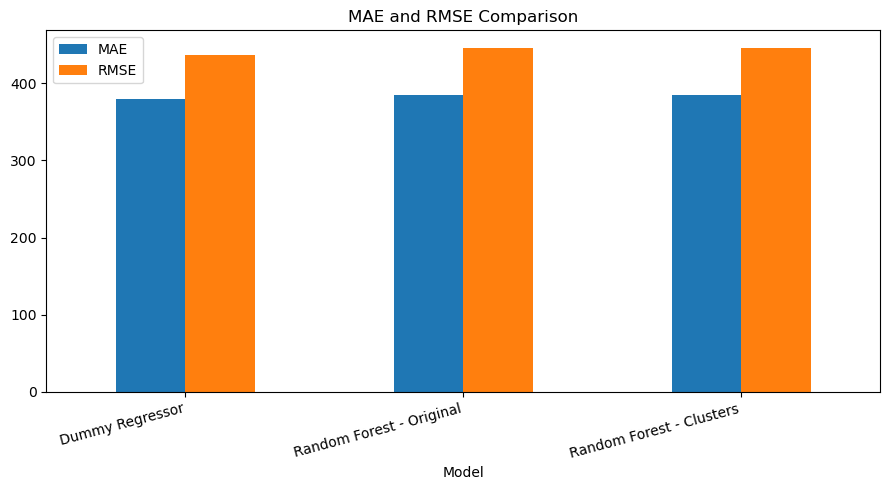

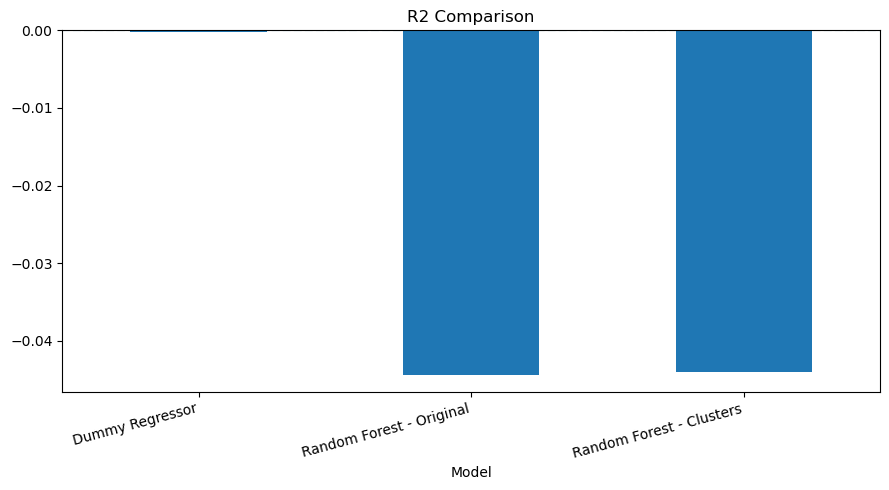

In [5]:
comparison.set_index("Model")[["MAE", "RMSE"]].plot(kind="bar", figsize=(9, 5))
plt.title("MAE and RMSE Comparison")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

comparison.set_index("Model")["R2"].plot(kind="bar", figsize=(9, 5))
plt.title("R2 Comparison")
plt.axhline(0, linestyle="--")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [6]:
os.makedirs("stage18_outputs", exist_ok=True)

comparison.to_csv("stage18_outputs/cluster_regression_comparison.csv", index=False)
pd.DataFrame(fold_results).to_csv("stage18_outputs/cluster_regression_fold_results.csv", index=False)

pd.DataFrame({
    "Actual_Yield": y.to_numpy(),
    "Dummy_Prediction": dummy_pred,
    "Original_RF_Prediction": rf_pred,
    "Cluster_RF_Prediction": cluster_pred
}).to_csv("stage18_outputs/cluster_regression_predictions.csv", index=False)

print("All Stage 18 outputs saved!")

All Stage 18 outputs saved!
